<a href="https://colab.research.google.com/github/Mehedi-Hasan-Robel/ML-project/blob/ml-project/Customer_Segmentation_RFM_%26_KMEANS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as plt
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [ ]:
df = pd.read_csv('/content/OnlineRetail.csv', encoding='latin1')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,12/01/2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,12/01/2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,12/01/2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,12/01/2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,12/01/2010 08:26,3.39,17850.0,United Kingdom


In [ ]:
df.tail(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
298641,563031,22384,LUNCH BAG PINK POLKADOT,2.0,08/11/2011 14:38,1.65,13263.0,United Kingdom
298642,563031,20727,LUNCH BAG BLACK SKULL.,1.0,08/11/2011 14:38,1.65,13263.0,United Kingdom
298643,563031,22383,LUNCH BAG SUKI DESIGN,2.0,08/11/2011 14:38,1.65,13263.0,United Kingdom
298644,563031,23208,LUNCH BAG VINTAGE LEAF DESIGN,1.0,08/11/2011 14:38,1.65,13263.0,United Kingdom
298645,563031,20725,LUNCH BAG RED RETROSPOT,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.shape

(298646, 8)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 298646 entries, 0 to 298645
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    298646 non-null  object 
 1   StockCode    298646 non-null  object 
 2   Description  297543 non-null  object 
 3   Quantity     298645 non-null  float64
 4   InvoiceDate  298645 non-null  object 
 5   UnitPrice    298645 non-null  float64
 6   CustomerID   214718 non-null  float64
 7   Country      298645 non-null  object 
dtypes: float64(3), object(5)
memory usage: 18.2+ MB


In [ ]:
df.dtypes

,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,float64
InvoiceDate,object
UnitPrice,float64
CustomerID,float64
Country,object


In [ ]:
currentdate = pd.to_datetime('2026-01-01')
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [ ]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
298641,563031,22384,LUNCH BAG PINK POLKADOT,2.0,2011-08-11 14:38:00,1.65,13263.0,United Kingdom
298642,563031,20727,LUNCH BAG BLACK SKULL.,1.0,2011-08-11 14:38:00,1.65,13263.0,United Kingdom
298643,563031,22383,LUNCH BAG SUKI DESIGN,2.0,2011-08-11 14:38:00,1.65,13263.0,United Kingdom
298644,563031,23208,LUNCH BAG VINTAGE LEAF DESIGN,1.0,2011-08-11 14:38:00,1.65,13263.0,United Kingdom


In [ ]:
currentdate

Timestamp('2026-01-01 00:00:00')

In [ ]:
df.dtypes

,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,float64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


In [ ]:
df.groupby(['CustomerID']).max()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country
CustomerID,,,,,,,
12346.0,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215.0,2011-01-18 10:17:00,1.04,United Kingdom
12347.0,562032,85232D,WOODLAND DESIGN COTTON TOTE BAG,240.0,2011-08-02 08:48:00,12.75,Iceland
12348.0,548955,POST,SWEETIES STICKERS,144.0,2011-04-05 10:47:00,40.00,Finland
12350.0,543037,POST,UNION JACK FLAG PASSPORT COVER,24.0,2011-02-02 16:01:00,40.00,Norway
12352.0,C547388,POST,WOODEN OWLS LIGHT GARLAND,12.0,2011-03-22 16:08:00,376.50,Norway
...,...,...,...,...,...,...,...
18280.0,545712,82484,WOODEN UNION JACK BUNTING,8.0,2011-03-07 09:52:00,9.95,United Kingdom
18281.0,556464,23209,ROBOT BIRTHDAY CARD,12.0,2011-06-12 10:53:00,16.95,United Kingdom
18282.0,C562808,23295,SET OF 12 MINI LOAF BAKING CASES,48.0,2011-08-09 15:10:00,12.75,United Kingdom


In [ ]:
maxdate = df.groupby(['CustomerID']).max()[['InvoiceDate']]
maxdate

,InvoiceDate
CustomerID,
12346.0,2011-01-18 10:17:00
12347.0,2011-08-02 08:48:00
12348.0,2011-04-05 10:47:00
12350.0,2011-02-02 16:01:00
12352.0,2011-03-22 16:08:00
...,...
18280.0,2011-03-07 09:52:00
18281.0,2011-06-12 10:53:00
18282.0,2011-08-09 15:10:00


In [ ]:
maxquantity = df.groupby(['CustomerID']).max()[['Quantity']]
maxquantity

,Quantity
CustomerID,
12346.0,74215.0
12347.0,240.0
12348.0,144.0
12350.0,24.0
12352.0,12.0
...,...
18280.0,8.0
18281.0,12.0
18282.0,48.0


In [ ]:
(currentdate-maxdate['InvoiceDate']).dt.days

,InvoiceDate
CustomerID,
12346.0,5461
12347.0,5265
12348.0,5384
12350.0,5446
12352.0,5398
...,...
18280.0,5413
18281.0,5316
18282.0,5258


In [ ]:
maxdate['InvoiceAge'] = (currentdate-maxdate['InvoiceDate']).dt.days
maxdate

,InvoiceDate,InvoiceAge
CustomerID,,
12346.0,2011-01-18 10:17:00,5461
12347.0,2011-08-02 08:48:00,5265
12348.0,2011-04-05 10:47:00,5384
12350.0,2011-02-02 16:01:00,5446
12352.0,2011-03-22 16:08:00,5398
...,...,...
18280.0,2011-03-07 09:52:00,5413
18281.0,2011-06-12 10:53:00,5316
18282.0,2011-08-09 15:10:00,5258


In [ ]:
recency = maxdate.drop('InvoiceDate',axis = 1)
recency

,InvoiceAge
CustomerID,
12346.0,5461
12347.0,5265
12348.0,5384
12350.0,5446
12352.0,5398
...,...
18280.0,5413
18281.0,5316
18282.0,5258


In [ ]:
frequency = df.drop_duplicates(subset = 'InvoiceNo')
frequency

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6.0,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32.0,2010-12-01 08:34:00,1.69,13047.0,United Kingdom
21,536368,22960,JAM MAKING SET WITH JARS,6.0,2010-12-01 08:34:00,4.25,13047.0,United Kingdom
25,536369,21756,BATH BUILDING BLOCK WORD,3.0,2010-12-01 08:35:00,5.95,13047.0,United Kingdom
...,...,...,...,...,...,...,...,...
298610,563027,22315,200 RED + WHITE BENDY STRAWS,1.0,2011-08-11 14:10:00,1.25,NaN,United Kingdom
298612,563028,84946,ANTIQUE SILVER T-LIGHT GLASS,12.0,2011-08-11 14:16:00,1.25,17629.0,United Kingdom
298616,563029,22810,SET OF 6 T-LIGHTS SNOWMEN,48.0,2011-08-11 14:34:00,2.55,18093.0,United Kingdom
298627,563030,22197,POPCORN HOLDER,12.0,2011-08-11 14:36:00,0.85,14834.0,United Kingdom


In [ ]:
frequency = frequency.groupby('CustomerID').count()[['InvoiceNo']]
frequency

,InvoiceNo
CustomerID,
12346.0,2
12347.0,5
12348.0,3
12350.0,1
12352.0,8
...,...
18280.0,1
18281.0,1
18282.0,2


In [ ]:
#monetary
df['total'] = df['Quantity']*df['UnitPrice']

In [ ]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,total
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
298641,563031,22384,LUNCH BAG PINK POLKADOT,2.0,2011-08-11 14:38:00,1.65,13263.0,United Kingdom,3.30
298642,563031,20727,LUNCH BAG BLACK SKULL.,1.0,2011-08-11 14:38:00,1.65,13263.0,United Kingdom,1.65
298643,563031,22383,LUNCH BAG SUKI DESIGN,2.0,2011-08-11 14:38:00,1.65,13263.0,United Kingdom,3.30
298644,563031,23208,LUNCH BAG VINTAGE LEAF DESIGN,1.0,2011-08-11 14:38:00,1.65,13263.0,United Kingdom,1.65


In [ ]:
monetary = df.groupby('CustomerID')[['total']].sum()
monetary

,total
CustomerID,
12346.0,0.00
12347.0,2790.86
12348.0,1487.24
12350.0,334.40
12352.0,601.18
...,...
18280.0,180.60
18281.0,80.82
18282.0,98.76


In [ ]:
#RFM
RFM = pd.concat([recency,frequency,monetary],axis = 1)
RFM

,InvoiceAge,InvoiceNo,total
CustomerID,,,
12346.0,5461,2,0.00
12347.0,5265,5,2790.86
12348.0,5384,3,1487.24
12350.0,5446,1,334.40
12352.0,5398,8,601.18
...,...,...,...
18280.0,5413,1,180.60
18281.0,5316,1,80.82
18282.0,5258,2,98.76


In [ ]:
RFM.columns = ['Recency','Frequency','Monetary']
RFM

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,5461,2,0.00
12347.0,5265,5,2790.86
12348.0,5384,3,1487.24
12350.0,5446,1,334.40
12352.0,5398,8,601.18
...,...,...,...
18280.0,5413,1,180.60
18281.0,5316,1,80.82
18282.0,5258,2,98.76


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled = scaler.fit_transform(RFM)

In [ ]:
scaled

array([[ 1.68268659, -0.30145501, -0.27493143],
       [-1.04402539,  0.16240592,  0.2766129 ],
       [ 0.61147831, -0.1468347 ,  0.01898471],
       ...,
       [-1.14140796, -0.30145501, -0.25541396],
       [-0.77970127,  0.78088715, -0.08011841],
       [-0.04237609, -0.45607532, -0.1236928 ]], shape=(3257, 3))

In [ ]:
scaled.shape

(3257, 3)

In [ ]:
# KMeans
from sklearn.cluster import KMeans

In [ ]:
k_range = range(1,11)
sse = []
for k in k_range:
  km = KMeans(n_clusters=k)
  km.fit(scaled)
  sse.append(km.inertia_)

In [ ]:
sse

[9770.999999999982,
 6657.233718222529,
 4057.9547098241146,
 3132.4151470706147,
 2375.186339985323,
 1927.7059276404252,
 1550.5916729501141,
 1306.507389479892,
 1130.4873843907587,
 1036.4204213667176]

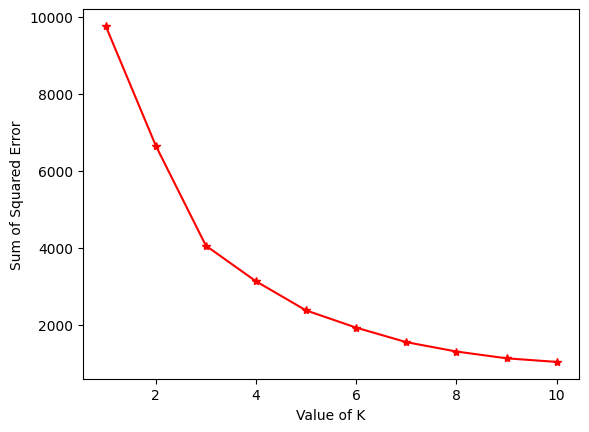

In [ ]:
plt.plot(k_range,sse,'r-*')
plt.xlabel('Value of K')
plt.ylabel('Sum of Squared Error')
plt.show()

In [ ]:
# object creation and data fitting
kmeans = KMeans(n_clusters=3)
kmeans.fit(scaled)


KMeans(n_clusters=3)

In [ ]:
kmeans.labels_

array([1, 0, 1, ..., 0, 0, 0], shape=(3257,), dtype=int32)

In [ ]:
kmeans.labels_.shape

(3257,)

In [ ]:
kmeans.labels_+1

array([2, 1, 2, ..., 1, 1, 1], shape=(3257,), dtype=int32)

In [ ]:
RFM['Clusters'] = (kmeans.labels_+1)
RFM

,Recency,Frequency,Monetary,Clusters
CustomerID,,,,
12346.0,5461,2,0.00,2
12347.0,5265,5,2790.86,1
12348.0,5384,3,1487.24,2
12350.0,5446,1,334.40,2
12352.0,5398,8,601.18,2
...,...,...,...,...
18280.0,5413,1,180.60,2
18281.0,5316,1,80.82,1
18282.0,5258,2,98.76,1


In [ ]:
RFM.Clusters.value_counts()

,count
Clusters,
1,2154
2,1078
3,25


In [ ]:
RFM.Clusters.unique()

array([2, 1, 3], dtype=int32)

In [ ]:
RFM[RFM.Clusters==1]

,Recency,Frequency,Monetary,Clusters
CustomerID,,,,
12347.0,5265,5,2790.86,1
12353.0,5340,1,89.00,1
12355.0,5350,1,459.40,1
12358.0,5286,1,484.86,1
12359.0,5325,4,3459.93,1
...,...,...,...,...
18272.0,5286,4,1720.40,1
18281.0,5316,1,80.82,1
18282.0,5258,2,98.76,1


In [ ]:
RFM[RFM.Clusters==2]

,Recency,Frequency,Monetary,Clusters
CustomerID,,,,
12346.0,5461,2,0.00,2
12348.0,5384,3,1487.24,2
12350.0,5446,1,334.40,2
12352.0,5398,8,601.18,2
12354.0,5368,1,1079.40,2
...,...,...,...,...
18269.0,5494,2,138.90,2
18270.0,5376,2,67.75,2
18273.0,5393,1,51.00,2


In [ ]:
RFM[RFM.Clusters==3]

,Recency,Frequency,Monetary,Clusters
CustomerID,,,,
12415.0,5279,15,76513.37,3
12748.0,5260,127,12517.21,3
12971.0,5262,61,7100.81,3
13089.0,5259,82,35545.87,3
13408.0,5256,49,16116.30,3
13694.0,5258,39,35755.45,3
13798.0,5259,45,26915.99,3
14156.0,5257,36,79273.36,3
14298.0,5259,36,35591.84,3


In [ ]:
def func(row):
  if row['Clusters']==1:
    return 'Gold'
  elif row['Clusters']==2:
    return 'Dimond'
  else:
    return 'Silver'


In [ ]:
RFM['group'] = RFM.apply(func,axis=1)

In [ ]:
RFM

,Recency,Frequency,Monetary,Clusters,group
CustomerID,,,,,
12346.0,5461,2,0.00,2,Dimond
12347.0,5265,5,2790.86,1,Gold
12348.0,5384,3,1487.24,2,Dimond
12350.0,5446,1,334.40,2,Dimond
12352.0,5398,8,601.18,2,Dimond
...,...,...,...,...,...
18280.0,5413,1,180.60,2,Dimond
18281.0,5316,1,80.82,1,Gold
18282.0,5258,2,98.76,1,Gold


In [ ]:
result = RFM.group.value_counts()
result

,count
group,
Gold,2154
Dimond,1078
Silver,25


<Axes: xlabel='group'>

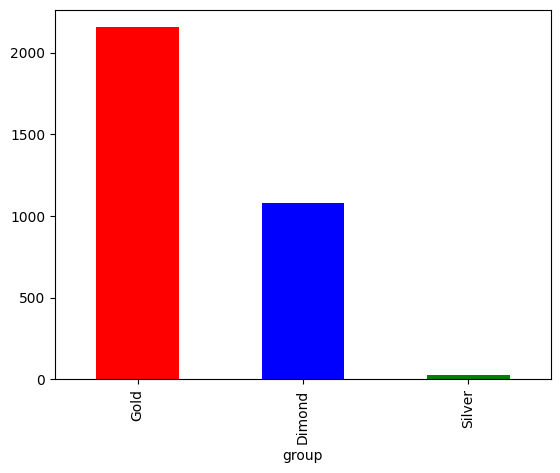

In [ ]:
result.plot(kind = 'bar',color = ['r','b','g'])

In [ ]:
ABC = RFM[RFM.Clusters==3]

In [ ]:
ABC[ABC['Monetary']==ABC['Monetary'].min()]

,Recency,Frequency,Monetary,Clusters,group
CustomerID,,,,,
14527.0,5258,58,4475.27,3,Silver


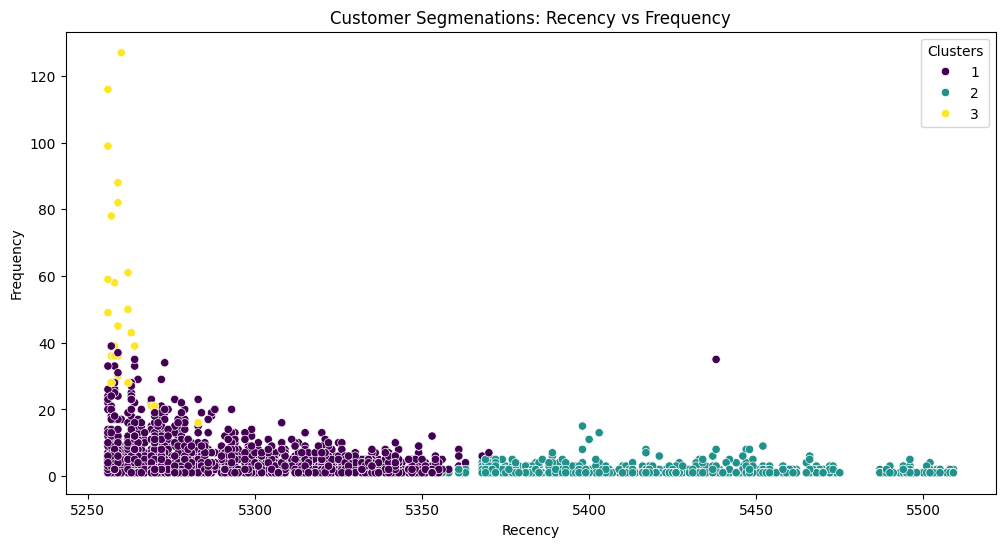

In [ ]:
import importlib
import matplotlib.pyplot as plt
importlib.reload(plt)
plt.figure(figsize = (12,6))
sns.scatterplot(x = 'Recency', y='Frequency',hue = 'Clusters',data = RFM, palette = 'viridis')
plt.xlabel('Recency')
plt.ylabel('Frequency')
plt.title('Customer Segmenations: Recency vs Frequency')
plt.show()


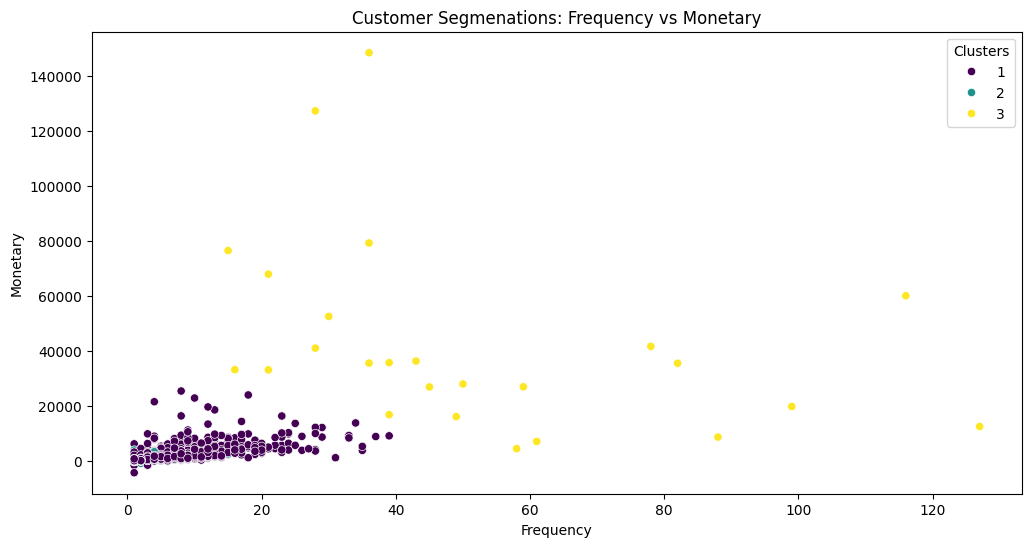

In [ ]:
plt.figure(figsize = (12,6))
sns.scatterplot(x = 'Frequency', y='Monetary',hue = 'Clusters',data = RFM, palette = 'viridis')
plt.xlabel('Frequency')
plt.ylabel('Monetary')
plt.title('Customer Segmenations: Frequency vs Monetary')
plt.show()

K = 2, Score = 0.8791
K = 3, Score = 0.5146
K = 4, Score = 0.5386
K = 5, Score = 0.5343
K = 6, Score = 0.5284
K = 7, Score = 0.4497
K = 8, Score = 0.4447
K = 9, Score = 0.4158
K = 10, Score = 0.4163


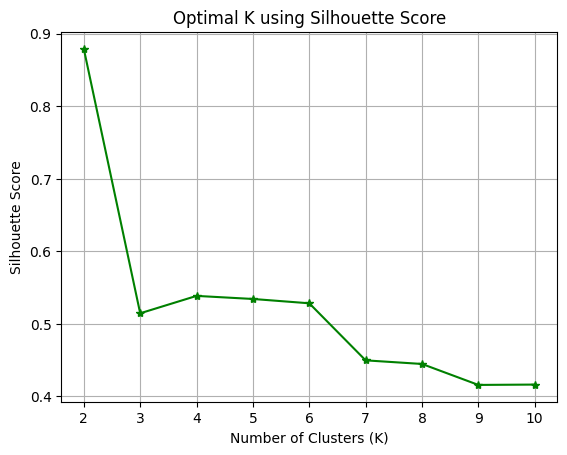

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

scores = []

for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(scaled)

    score = silhouette_score(scaled, labels)
    scores.append(score)

    print(f"K = {k}, Score = {score:.4f}")

plt.plot(range(2, 11), scores, 'g-*')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Optimal K using Silhouette Score')
plt.grid()
plt.show()